# code_171 · Historical action support and honest policy evaluation

**Book:** section 32.5. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_171).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5371;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5371


<a id="support-constrained-offline-learning"></a>
 ## Fit only from historical actions and preserve the missing column
 The maintenance simulator has three conditions and three actions: wait, repair and overhaul. Behavior chooses wait with probability 0.8 and repair 0.2 in every state; overhaul has exactly zero probability. Generate 200 fitting episodes and 800 independent evaluation episodes of eight steps, each starting healthy. Fitting and evaluation logs are distinct. Fitted Q iteration uses observed transition averages; unobserved entries remain at an explicitly optimistic initial value 5 in the unrestricted variant. The support-constrained variant permits only actions observed at least ten times in that state. This is a simple support restriction, not a reproduction of CQL's regularized objective or its theoretical lower bound. A fixed stochastic candidate repairs with probability 0.4 when failed and 0.1 otherwise. It is evaluated without using evaluation records to select or fit it.


,Wait,Repair,Overhaul
0,824,240,0
1,290,72,0
2,143,31,0


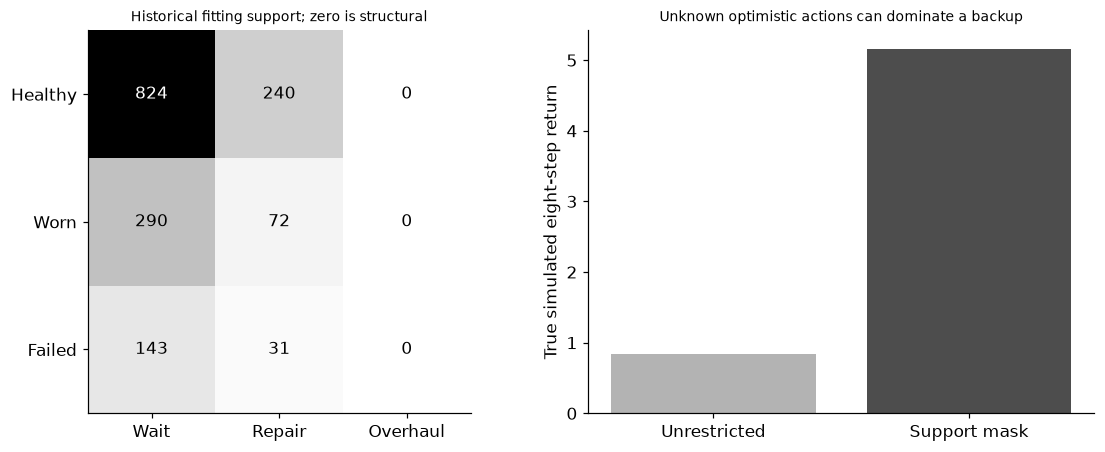

In [2]:
H=8;P=np.array([[[.8,.2,0],[.9,.1,0],[1.,0,0]],[[0,.7,.3],[.9,.1,0],[1.,0,0]],[[0,0,1],[.9,.1,0],[1.,0,0]]]);R=np.array([[1.,-1.2,-5.],[.2,-1.2,-5.],[-4.,-1.2,-5.]]);behavior=np.tile([.8,.2,0.],(3,1));candidate=np.array([[.9,.1,0.],[.9,.1,0.],[.6,.4,0.]])
def logs(n,seed):
    gr=np.random.default_rng(seed);out=[]
    for episode in range(n):
        s=0;trajectory=[]
        for t in range(H):a=int(gr.choice(3,p=behavior[s]));ns=int(gr.choice(3,p=P[s,a]));trajectory.append((s,a,float(R[s,a]),ns));s=ns
        out.append(trajectory)
    return np.array(out)
train=logs(200,SEED);evaluation=logs(800,SEED+100);counts=np.zeros((3,3),int);Phat=np.zeros_like(P);Rhat=np.zeros_like(R)
for s,a,r,ns in train.reshape(-1,4):s,a,ns=int(s),int(a),int(ns);counts[s,a]+=1;Phat[s,a,ns]+=1;Rhat[s,a]+=r
for s in range(3):
    for a in range(3):
        if counts[s,a]:Phat[s,a]/=counts[s,a];Rhat[s,a]/=counts[s,a]
supported=counts>=10
np.testing.assert_allclose(Phat[supported].sum(1),1.)
def require_support(pi):
    if np.any((pi>0)&(behavior==0)):raise ValueError('Candidate assigns probability to an unsupported action')
require_support(candidate)
def fitted(restrict):
    q=np.full((3,3),5.)
    for k in range(100):
        mx=np.where(supported,q,-1e9).max(1) if restrict else q.max(1);target=Rhat+.9*np.einsum('sak,k->sa',Phat,mx);q=np.where(counts>0,target,q)
    pi=np.where(supported,q,-1e9).argmax(1) if restrict else q.argmax(1);return q,pi
uq,up=fitted(False);cq,cp=fitted(True)
def finite_values(policy,reward,transition):
    v=np.zeros((H+1,3));q=np.zeros((H,3,3))
    for t in reversed(range(H)):q[t]=reward+np.einsum('sak,k->sa',transition,v[t+1]);v[t]=np.sum(policy*q[t],1)
    return v,q
true_v,_=finite_values(candidate,R,P);model_v,model_q=finite_values(candidate,Rhat,Phat)
def policy_return(pi):return float(finite_values(np.eye(3)[pi],R,P)[0][0,0])
assert np.all(counts[:,2]==0) and np.all(supported[:,:2]) and train.shape==(200,H,4) and not np.any(candidate[behavior==0]>0)
RESULTS.update(training_episodes=200,evaluation_episodes=800,horizon=H,behavior_probabilities=behavior.tolist(),training_action_counts=counts.tolist(),unrestricted_policy=up.tolist(),support_constrained_policy=cp.tolist(),unrestricted_true_return=policy_return(up),support_constrained_true_return=policy_return(cp),unsupported_initial_Q=5.,support_minimum_count=10,fit_iterations=100,fit_discount=.9,candidate_true_finite_return=float(true_v[0,0]))
display(pd.DataFrame(counts,columns=['Wait','Repair','Overhaul']));fig,axes=plt.subplots(1,2,figsize=(10,4));im=axes[0].imshow(counts,cmap='Greys');axes[0].set(xticks=range(3),xticklabels=['Wait','Repair','Overhaul'],yticks=range(3),yticklabels=['Healthy','Worn','Failed'],title='Historical fitting support; zero is structural')
for s in range(3):
    for a in range(3):axes[0].text(a,s,str(counts[s,a]),ha='center',va='center',color='white' if counts[s,a]>counts.max()/2 else 'black')
axes[1].bar([0,1],[policy_return(up),policy_return(cp)],color=['.7','.3']);axes[1].set(xticks=[0,1],xticklabels=['Unrestricted','Support mask'],ylabel='True simulated eight-step return',title='Unknown optimistic actions can dominate a backup');plt.show()


<a id="dr-and-nonidentification"></a>
 ## Evaluate a supported policy; refuse an unsupported one
 Trajectory IS multiplies candidate/behavior probabilities along all eight steps. Sequential doubly robust evaluation uses the independently fitted time-indexed Q/V model and importance-corrected residuals. Resample whole evaluation episodes 300 times for descriptive percentile intervals; finite samples and extreme weights can still defeat nominal coverage. We report trajectory effective sample size, not merely 800 records. For an all-overhaul candidate, weighting is undefined because behavior never took that action. Two simulator worlds with overhaul reward−5 or+5 produce exactly the same observed logs but very different candidate returns. This proves lack of identification; a narrow interval from any extrapolating model would not repair it.


,mean,episode_SD,bootstrap_95_percentile
Trajectory IS,1.431109,6.791695,"[1.0253871530927727, 1.9282637546963994]"
Sequential DR,1.673035,4.333482,"[1.3681502052722827, 1.9564305463972658]"


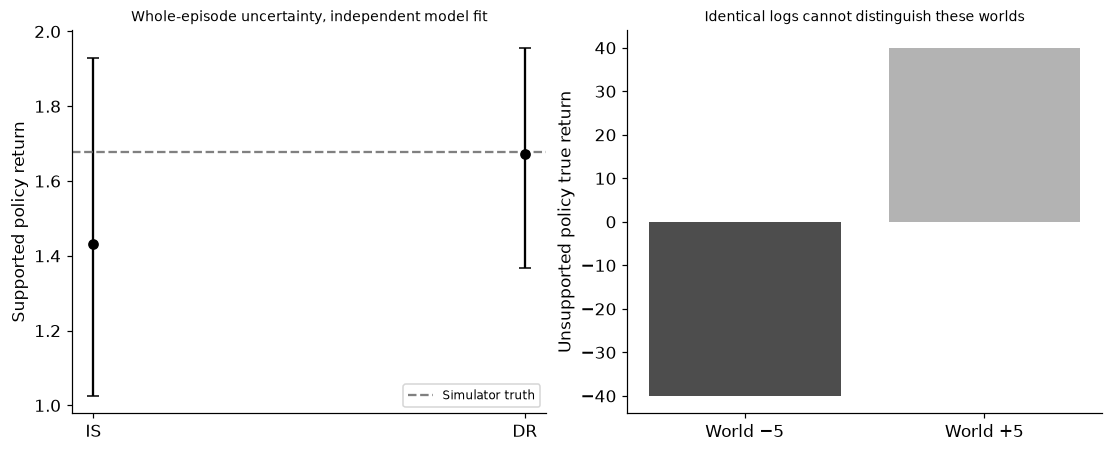

In [3]:
is_values=[];dr_values=[];weights=[]
for trajectory in evaluation:
    rho=1.;total=0.;ratios=[]
    for t,(ss,aa,r,nnx) in enumerate(trajectory):
        s,a=int(ss),int(aa);ratio=candidate[s,a]/behavior[s,a];ratios.append(ratio);rho*=ratio;total+=r
    is_values.append(rho*total);weights.append(rho);dr=0.
    for t in reversed(range(H)):
        s,a,r,ns=trajectory[t];s,a=int(s),int(a);dr=model_v[t,s]+ratios[t]*(r+dr-model_q[t,s,a])
    dr_values.append(dr)
is_values=np.array(is_values);dr_values=np.array(dr_values);weights=np.array(weights);boot_rng=np.random.default_rng(SEED+200);ids=boot_rng.integers(0,800,(300,800));estimates={}
for name,values in [('Trajectory IS',is_values),('Sequential DR',dr_values)]:estimates[name]={'mean':float(values.mean()),'episode_SD':float(values.std(ddof=1)),'bootstrap_95_percentile':np.quantile(values[ids].mean(1),[.025,.975]).tolist()}
unsupported=np.tile([0.,0.,1.],(3,1));world2=R.copy();world2[:,2]=5.;world_values=[float(finite_values(unsupported,reward,P)[0][0,0]) for reward in [R,world2]];uncovered=False
try:require_support(unsupported)
except ValueError:uncovered=True
assert uncovered and world_values==[-40.,40.] and np.allclose(R[:,:2],world2[:,:2]) and np.isfinite(dr_values).all()
RESULTS.update(offline_evaluation=estimates,trajectory_weight_sum=float(weights.sum()),trajectory_effective_sample_size=float(weights.sum()**2/np.sum(weights**2)),max_trajectory_weight=float(weights.max()),bootstrap_episode_resamples=300,unsupported_policy_weighting_refused=uncovered,compatible_world_unsupported_values=world_values,evaluation_outcomes_used_for_fitting=0)
display(pd.DataFrame(estimates).T);fig,axes=plt.subplots(1,2,figsize=(10,4));names=list(estimates);means=[estimates[k]['mean'] for k in names];intervals=np.array([estimates[k]['bootstrap_95_percentile'] for k in names]);axes[0].errorbar(range(2),means,yerr=np.array([np.array(means)-intervals[:,0],intervals[:,1]-means]),fmt='o',color='black',capsize=4);axes[0].axhline(true_v[0,0],color='.5',linestyle='--',label='Simulator truth');axes[0].set(xticks=range(2),xticklabels=['IS','DR'],ylabel='Supported policy return',title='Whole-episode uncertainty, independent model fit');axes[0].legend(fontsize=8);axes[1].bar([0,1],world_values,color=['.3','.7']);axes[1].set(xticks=[0,1],xticklabels=['World −5','World +5'],ylabel='Unsupported policy true return',title='Identical logs cannot distinguish these worlds');plt.show()


In [4]:
summary={'example_id':'code_171','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['real fixed logged behavior trajectories with structural action noncoverage', 'unrestricted versus support-constrained fitted Q iteration', 'independent ordinary trajectory importance sampling and sequential doubly robust evaluation', 'whole-episode bootstrap and trajectory effective sample size', 'two observationally compatible worlds proving unsupported value nonidentification'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["real fixed logged behavior trajectories with structural action noncoverage", "unrestricted versus support-constrained fitted Q iteration", "independent ordinary trajectory importance sampling and sequential doubly robust evaluation", "whole-episode bootstrap and trajectory effective sample size", "two observationally compatible worlds proving unsupported value nonidentification"], "elapsed_seconds": 0.522, "example_id": "code_171", "hardware": "Darwin arm64 CPU", "results": {"behavior_probabilities": [[0.8, 0.2, 0.0], [0.8, 0.2, 0.0], [0.8, 0.2, 0.0]], "bootstrap_episode_resamples": 300, "candidate_true_finite_return": 1.6788120435003009, "compatible_world_unsupported_values": [-40.0, 40.0], "evaluation_episodes": 800, "evaluation_outcomes_used_for_fitting": 0, "fit_discount": 0.9, "fit_iterations": 100, "horizon": 8, "max_trajectory_weight": 4.561394691467285, "offline_evaluation": {"Sequential DR": {"bootstrap_95_percentile": [1.3681